# Inspecting the reconstruction result

The reconstruction result [spring.Result](#spring.Result) is returned by the `spring.MPR.run()` method, which allows for an immediate inspection of the phase retrieval outcome. 

However, the result is also saved on disk at the path indicated in the settings. By default, the path is set to `./`, i.e. the folder where the reconstruction script was executed:

In [9]:
from spring import Settings
Settings().info('global','workdir')

| Section |   Name  | Value |  Type  | Range |           Description            |
| :-----: | :-----: | :---: | :----: | :---: | :------------------------------: |
|         | workdir |   ./  | string |       | Path where the results are saved |


The filename is composed by concatenating the numbers contained in the `pid` parameter of the pattern object with an underscore, and then adding the `_rec.h5` suffix. The file is saved in `HDF5` format, and can be manually loaded and inspected via the [h5py](https://www.h5py.org/) python module.

However, the `spring.Result` class provides an interface to handle the reconstruction files in an easier way.
In particular, it is possible to load a reconstruction from the storage by providing the `pid` (and the `workdir` if different from the current directory). For example:

In [2]:
# Get the pid of the diffraction pattern
import numpy as np

data = np.load('data/example_A_1.npz')
print(*data['pid'])

# Load the reconstruction
from spring import Result
rec = Result(data['pid'])

197 10 14558540587


It is possible to see how the filename is formatted by using the `spring.Result.get_filename` method of a reconstruction:

In [3]:
print(Result().get_filename(pid=data['pid']))
print(Result().get_filename(pid=[123,456789], tag='test1'))

197_10_14558540587_rec.h5
123_456789_test1_rec.h5


The filename can be then also manually specified using the `spring.Result.loadfile` method and indicating the full path to the file, i.e.:

In [8]:
rec_manual = Result().loadfile('./197_10_14558540587_rec.h5')

The quickest way to get an overview on the result is to call the `spring.Result.plot()` method

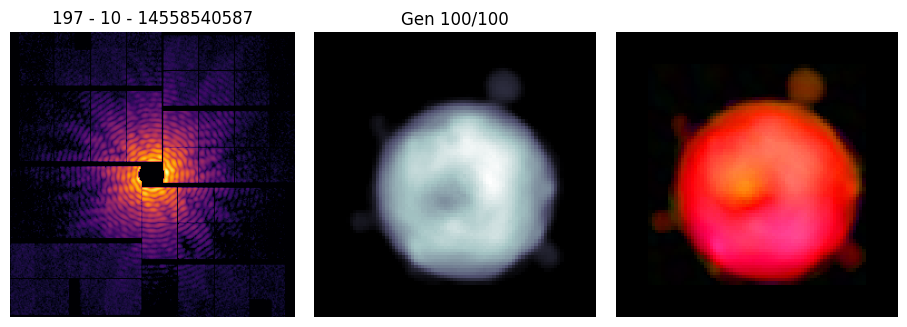

In [5]:
rec.plot()

Further information can be gained by adding the `stats=True` option, which reports the behavior of some performance indicators along the reconstruction process

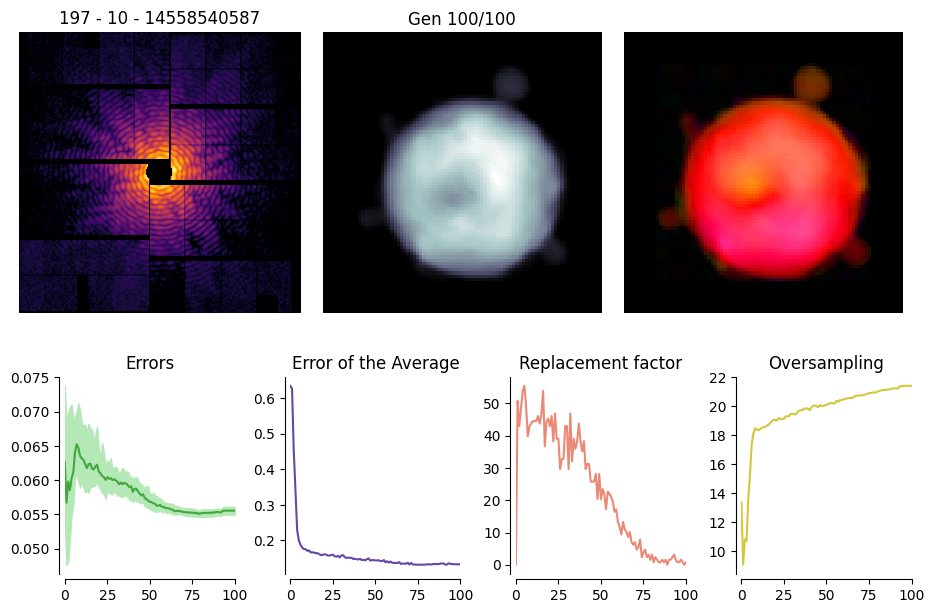

In [6]:
rec.plot(stats=True)

It is possible to *manually* fill a plot with a custom layout and a custom content, for example in the following way:

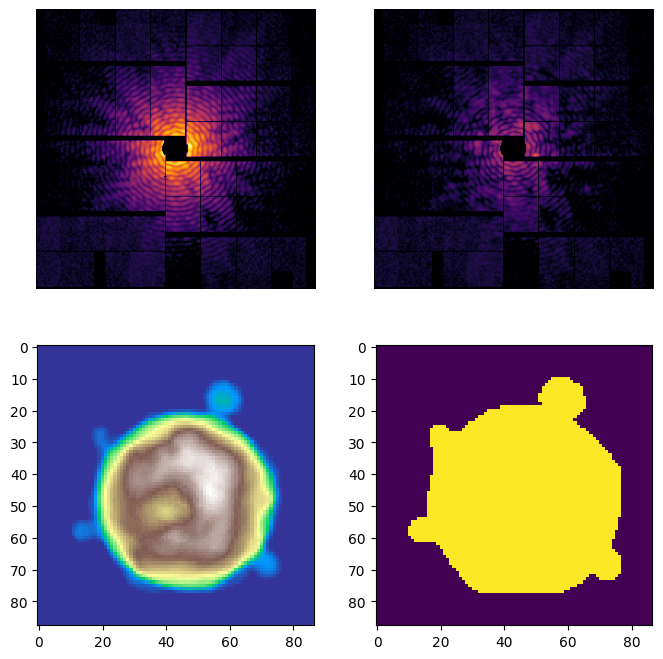

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2,2, figsize=(8,8))
rec.plot_pattern(ax[0][0])
rec.plot_residuals(ax[0][1])
rec.plot_density(ax[1][0], cmap='terrain')
rec.plot_support(ax[1][1])
ax[1][0].axis('on')
ax[1][1].axis('on')
plt.show()
